URL for report: https://api.wandb.ai/links/rudrasomaiya-vijaybhoomi-university/8n0e6k8l

# White-Box Audit of SmolLM-135M

white-box safety audit of SmolLM-135M before deploying it for automated text completion

1. **Attention patterns** -- does the model track pronoun references correctly?
2. **Gradient attribution** -- which input words actually drive the model's predictions?
3. **Latent space structure** -- does the model internally separate different topics?

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
import warnings
from transformers import AutoModelForCausalLM, AutoTokenizer
from captum.attr import IntegratedGradients, NoiseTunnel
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from IPython.display import display, HTML

d:\Uni Stuff\Final Independence Term\ExplainableAI\EndTerm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports loaded.


In [ ]:
import wandb
wandb.login()

run = wandb.init(
    project="xai-endterm-audit",
    name="smollm-135m-whitebox-audit",
    config={
        "model": "HuggingFaceTB/SmolLM-135M",
        "device": "cpu",
        "ig_steps": 50,
        "smoothgrad_samples": 15,
    }
)
print("W&B run URL:", run.url)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\rudra\_netrc.
wandb: Currently logged in as: rudrasomaiya (rudrasomaiya-vijaybhoomi-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B run URL: https://wandb.ai/rudrasomaiya-vijaybhoomi-university/xai-endterm-audit/runs/n0r5toqy


In [ ]:
model_name = "HuggingFaceTB/SmolLM-135M"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32,        # float32 keeps gradients stable for captum
    attn_implementation="eager"       # needed so output_attentions actually works
)
model.eval()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Model loaded:", model_name)
print("  Layers:", model.config.num_hidden_layers)
print("  Query heads per layer:", model.config.num_attention_heads)
print("  KV heads per layer:", model.config.num_key_value_heads)
print("  Hidden size:", model.config.hidden_size)
print("  Vocab size:", model.config.vocab_size)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 919.40it/s]


Model loaded: HuggingFaceTB/SmolLM-135M
  Layers: 30
  Query heads per layer: 9
  KV heads per layer: 3
  Hidden size: 576
  Vocab size: 49152


## Objective 1: Attention Heatmap

We want to see what the model "looks at" when it processes a sentence with a pronoun.. The question is: when the model reads "she", which earlier word does it pay the most attention to?

We use a simple sentence where "she" clearly refers to "nurse":

> The nurse examined the patient and she prescribed the medication.

- **Plot A**: all 9 heads in the best layer (the full picture, nothing hidden)
- **Plot B**: the 2-3 most interesting heads zoomed in with annotations

In [7]:
sentence = "The nurse examined the patient and she prescribed the medication."
inputs = tokenizer(sentence, return_tensors="pt")
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:")
for i, t in enumerate(tokens):
    print(f"  [{i}] {t}")

# helper to clean up tokenizer artifacts for matching
def clean_token(tok):
    return tok.replace("▁", "").replace("Ġ", "").lower().strip()

# Find "she" and "nurse" positions
she_idx = None
nurse_idx = None
for i, tok in enumerate(tokens):
    c = clean_token(tok)
    if c == "she" and she_idx is None:
        she_idx = i
    if c == "nurse" and nurse_idx is None:
        nurse_idx = i

print()
print("she found at index", she_idx)
print("nurse found at index", nurse_idx)

Tokens:
  [0] The
  [1] Ġnurse
  [2] Ġexamined
  [3] Ġthe
  [4] Ġpatient
  [5] Ġand
  [6] Ġshe
  [7] Ġprescribed
  [8] Ġthe
  [9] Ġmedication
  [10] .

she found at index 6
nurse found at index 1


In [8]:
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

attentions = outputs.attentions  # tuple of 30 tensors, each (1, 9, seq_len, seq_len)
num_layers = len(attentions)
num_heads = attentions[0].shape[1]
print("Got attention from", num_layers, "layers,", num_heads, "heads each")
print("Attention shape per layer:", attentions[0].shape)

# Scan every layer and head for the strongest she -> nurse connection
all_scores = []
for layer_i in range(num_layers):
    for head_i in range(num_heads):
        w = attentions[layer_i][0, head_i, she_idx, nurse_idx].item()
        all_scores.append((layer_i, head_i, w))

all_scores.sort(key=lambda x: x[2], reverse=True)

print()
print("Top 10 heads for she -> nurse attention:")
for layer_i, head_i, w in all_scores[:10]:
    print(f"  Layer {layer_i}, Head {head_i}: {w:.4f}")

best_layer, best_head, best_weight = all_scores[0]
print()
print(f"Best: Layer {best_layer}, Head {best_head} (weight = {best_weight:.4f})")

Got attention from 30 layers, 9 heads each
Attention shape per layer: torch.Size([1, 9, 11, 11])

Top 10 heads for she -> nurse attention:
  Layer 5, Head 8: 0.6007
  Layer 5, Head 6: 0.5960
  Layer 15, Head 3: 0.4286
  Layer 16, Head 6: 0.4235
  Layer 12, Head 7: 0.3466
  Layer 15, Head 5: 0.2654
  Layer 23, Head 3: 0.2287
  Layer 0, Head 8: 0.1859
  Layer 29, Head 5: 0.1756
  Layer 0, Head 6: 0.1732

Best: Layer 5, Head 8 (weight = 0.6007)


In [9]:
she_idx = None
nurse_idx = None

for i, tok in enumerate(tokens):
    stripped = tok.replace('Ġ', '').replace('▁', '').lower().strip()
    if stripped == 'she':
        she_idx = i
    if stripped == 'nurse':
        nurse_idx = i

print("she_idx:", she_idx)   # should be 6
print("nurse_idx:", nurse_idx)  # should be 1

she_idx: 6
nurse_idx: 1


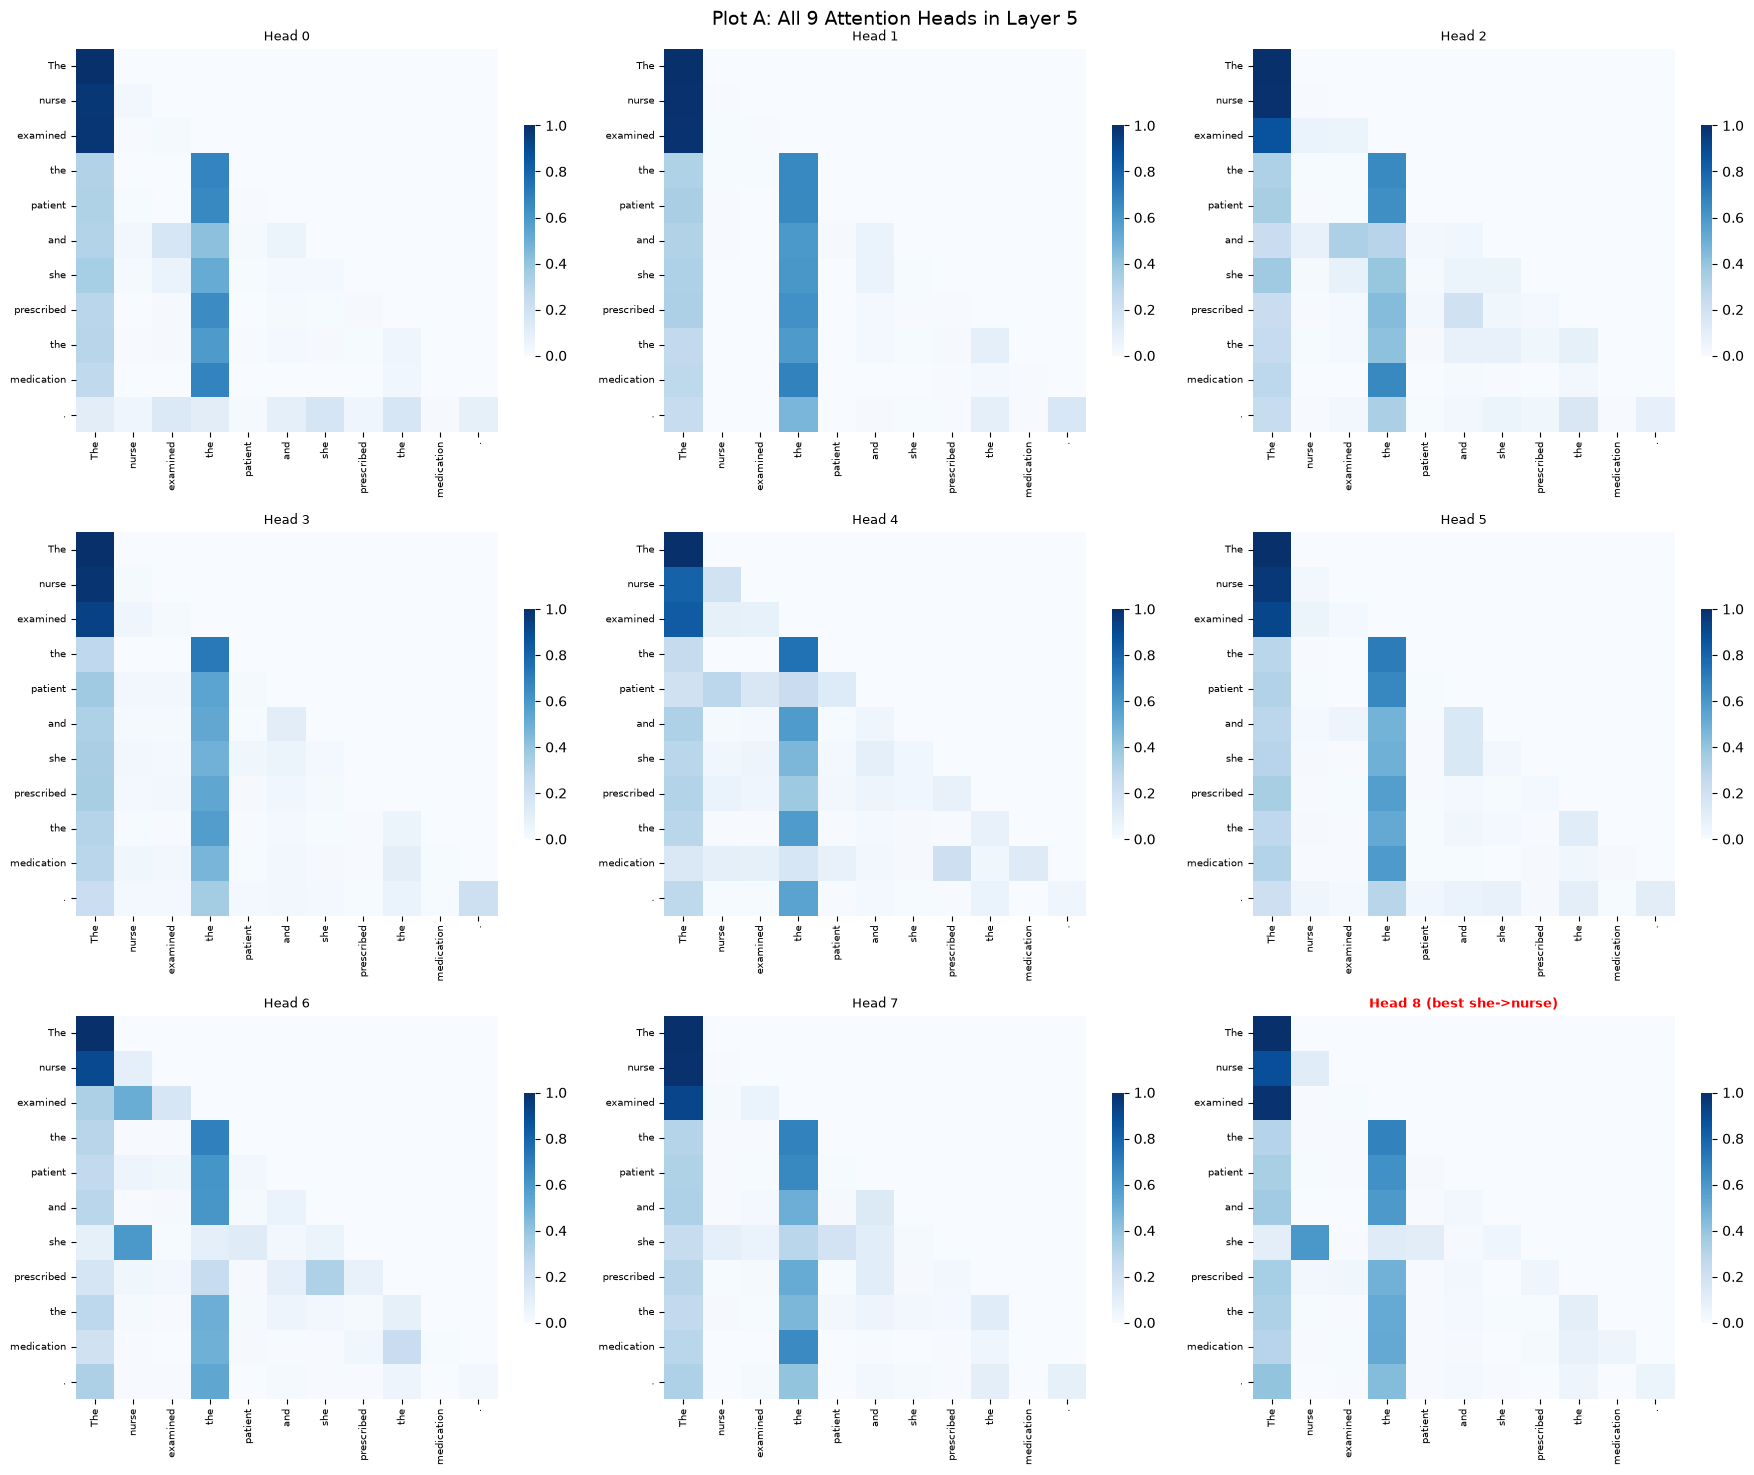

In [10]:
# Clean up token labels for plot axes
token_labels = []
for t in tokens:
    label = t.replace("▁", " ").replace("Ġ", " ").strip()
    if label == "":
        label = t
    token_labels.append(label)

layer_attn = attentions[best_layer][0].detach().numpy()  # shape (9, seq_len, seq_len)

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle(f"Plot A: All 9 Attention Heads in Layer {best_layer}", fontsize=14)

for h in range(9):
    row, col = h // 3, h % 3
    ax = axes[row][col]

    sns.heatmap(
        layer_attn[h],
        xticklabels=token_labels,
        yticklabels=token_labels,
        cmap="Blues",
        vmin=0,
        ax=ax,
        cbar_kws={"shrink": 0.6}
    )
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

    title = f"Head {h}"
    if h == best_head:
        title += " (best she->nurse)"
        ax.set_title(title, fontsize=9, color="red", fontweight="bold")
    else:
        ax.set_title(title, fontsize=9)

plt.tight_layout()
wandb.log({"attention/all_heads_layer": wandb.Image(fig)})
plt.show()

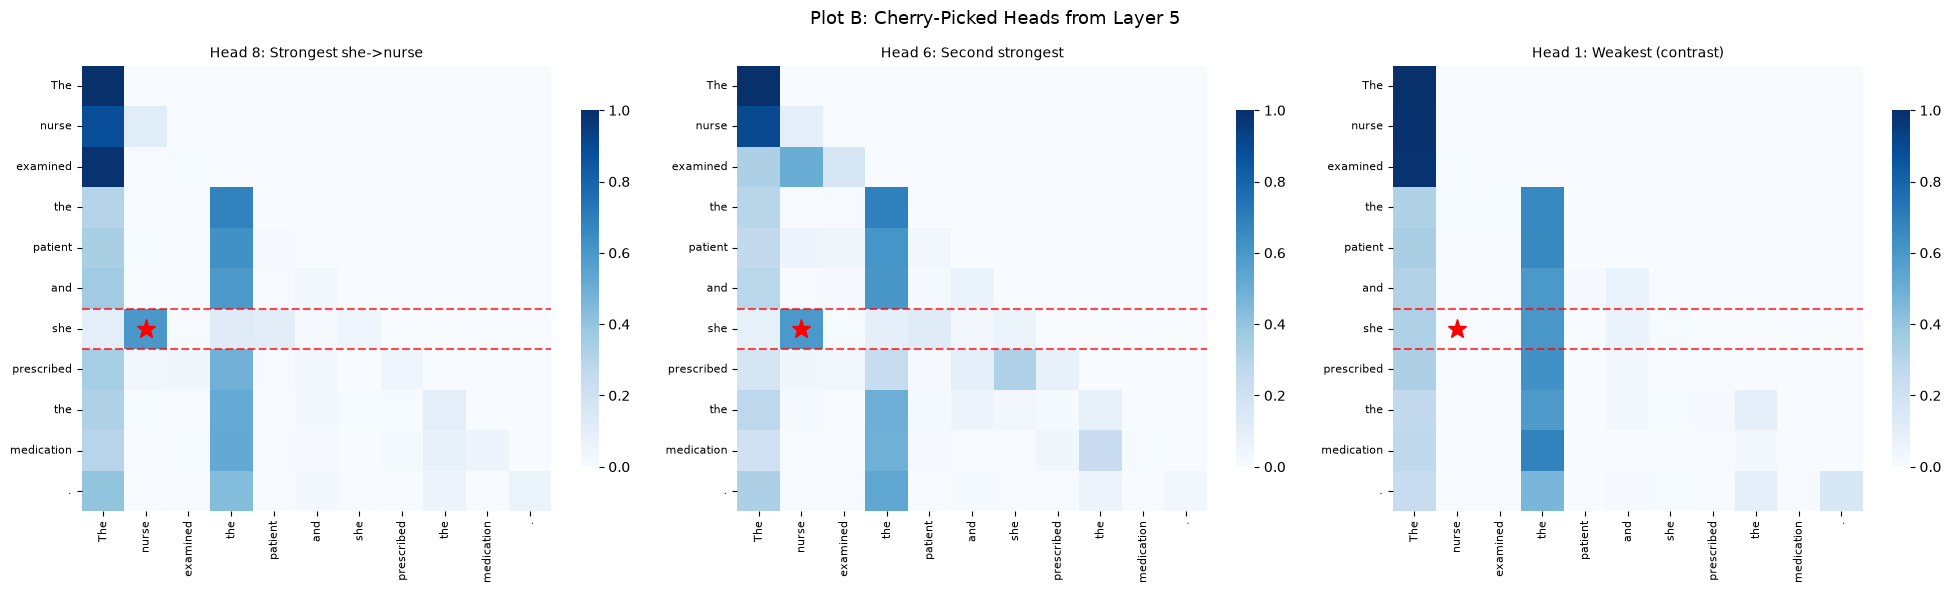


Attention from she in the best head (Layer 5, Head 8):
              The: 0.1035
            nurse: 0.6007  <-- HIGHEST
         examined: 0.0067
              the: 0.1240
          patient: 0.1061
              and: 0.0130
              she: 0.0459
       prescribed: 0.0000
              the: 0.0000
       medication: 0.0000
                .: 0.0000


In [11]:
# Pick: best head, second best, and weakest (for contrast)
layer_head_scores = [
    (h, attentions[best_layer][0, h, she_idx, nurse_idx].item())
    for h in range(num_heads)
]
layer_head_scores.sort(key=lambda x: x[1], reverse=True)

chosen = [
    (layer_head_scores[0][0], "Strongest she->nurse"),
    (layer_head_scores[1][0], "Second strongest"),
    (layer_head_scores[-1][0], "Weakest (contrast)"),
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle(f"Plot B: Cherry-Picked Heads from Layer {best_layer}", fontsize=13)

for idx, (h, label) in enumerate(chosen):
    ax = axes[idx]
    head_attn = layer_attn[h]

    sns.heatmap(
        head_attn,
        xticklabels=token_labels,
        yticklabels=token_labels,
        cmap="Blues",
        vmin=0,
        ax=ax,
        cbar_kws={"shrink": 0.8}
    )
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    ax.set_title(f"Head {h}: {label}", fontsize=10)

    # Red dashed lines around the "she" row
    ax.axhline(y=she_idx, color="red", linewidth=1.5, linestyle="--", alpha=0.7)
    ax.axhline(y=she_idx + 1, color="red", linewidth=1.5, linestyle="--", alpha=0.7)

    # Star on the nurse column in the she row
    ax.plot(nurse_idx + 0.5, she_idx + 0.5, "r*", markersize=14)

plt.tight_layout()
wandb.log({"attention/cherry_picked_heads": wandb.Image(fig)})
plt.show()

# Print the full attention distribution from "she" in the best head
print()
print(f"Attention from she in the best head (Layer {best_layer}, Head {best_head}):")
she_row = layer_attn[best_head][she_idx]
for i, (tok, weight) in enumerate(zip(token_labels, she_row)):
    marker = "  <-- HIGHEST" if i == she_row.argmax() else ""
    print(f"  {tok:>15s}: {weight:.4f}{marker}")

Tokens for the three-names sentence:
  [0] G
  [1] ay
  [2] atri
  [3] ,
  [4] ĠD
  [5] aksh
  [6] ya
  [7] Ġand
  [8] ĠSh
  [9] ra
  [10] van
  [11] i
  [12] Ġwent
  [13] Ġto
  [14] Ġthe
  [15] Ġlibrary
  [16] Ġand
  [17] Ġshe
  [18] Ġpicked
  [19] Ġup
  [20] Ġa
  [21] Ġbook
  [22] Ġon
  [23] Ġhistory
  [24] .

she is at index 17


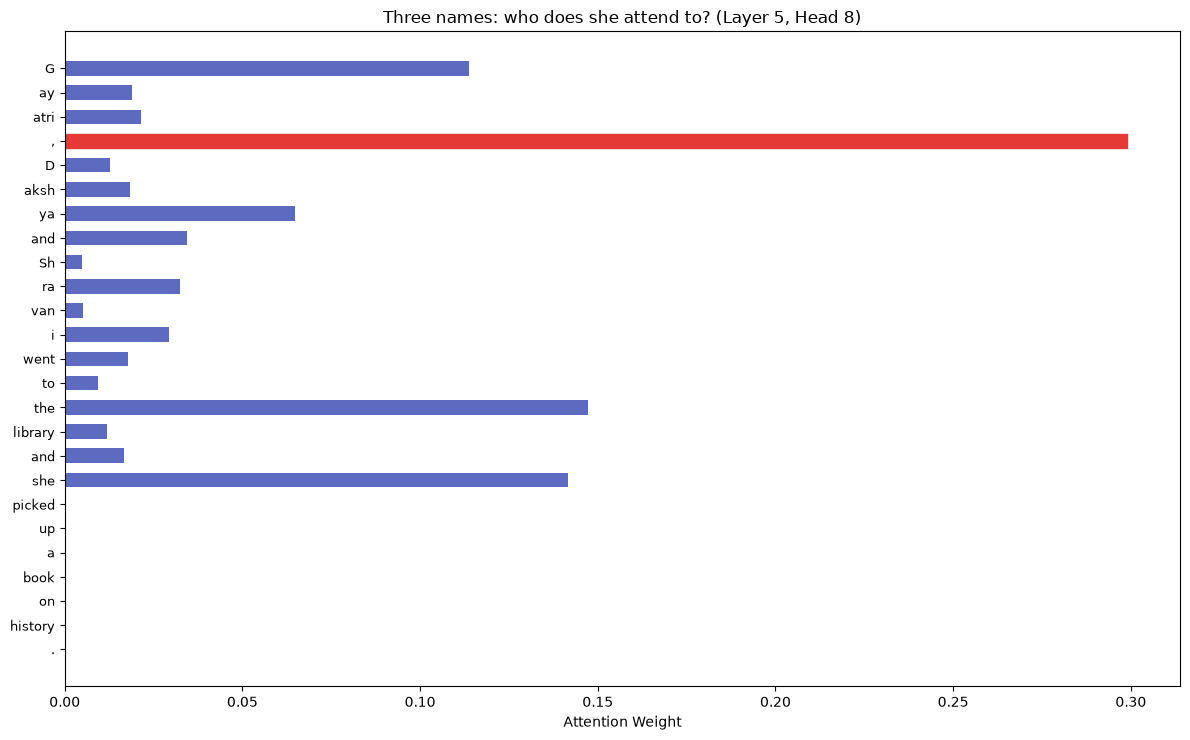


The model attends most from she to: , (weight = 0.2989)


In [ ]:
sentence2 = "Gayatri, Dakshya and Shravani went to the library and she picked up a book on history."
inputs2 = tokenizer(sentence2, return_tensors="pt")
tokens2 = tokenizer.convert_ids_to_tokens(inputs2["input_ids"][0])

print("Tokens for the three-names sentence:")
for i, t in enumerate(tokens2):
    print(f"  [{i}] {t}")

# Find "she" in this sentence
she_idx2 = None
for i, tok in enumerate(tokens2):
    c = clean_token(tok)
    if c == "she" and she_idx2 is None:
        she_idx2 = i
print()
print("she is at index", she_idx2)

with torch.no_grad():
    outputs2 = model(**inputs2, output_attentions=True)

# Use the same best layer/head from the nurse analysis
attn2 = outputs2.attentions[best_layer][0, best_head, she_idx2, :].detach().numpy()

# Clean labels
token_labels2 = []
for t in tokens2:
    label = t.replace("▁", " ").replace("Ġ", " ").strip()
    if label == "":
        label = t
    token_labels2.append(label)

# Bar chart: where does "she" look?
fig, ax = plt.subplots(figsize=(12, max(4, len(tokens2) * 0.3)))
bars = ax.barh(range(len(token_labels2)), attn2, color="#5C6BC0", height=0.6)
ax.set_yticks(range(len(token_labels2)))
ax.set_yticklabels(token_labels2, fontsize=9)
ax.set_xlabel("Attention Weight")
ax.set_title(f"Three names: who does she attend to? (Layer {best_layer}, Head {best_head})")
ax.invert_yaxis()

# Highlight the top-attended token
max_idx = int(attn2.argmax())
bars[max_idx].set_color("#E53935")

plt.tight_layout()
wandb.log({"attention/three_names_bar": wandb.Image(fig)})
plt.show()

print()
print(f"The model attends most from she to: {token_labels2[max_idx]} (weight = {attn2[max_idx]:.4f})")

# Log scalar metrics
wandb.log({
    "attention/best_layer": best_layer,
    "attention/best_head": best_head,
    "attention/she_to_nurse_weight": best_weight,
    "attention/three_names_top_token": token_labels2[max_idx],
    "attention/three_names_top_weight": float(attn2[max_idx]),
})

## Objective 2: Attribution Scores (Integrated Gradients + SmoothGrad)

Attention shows what the model "looks at", but that is not the same as what actually drives the prediction. Attribution methods use gradients to answer a different question: if I changed or removed this word, how much would the output change?

We use the same nurse sentence and run two methods:

1. **Integrated Gradients (IG)**: traces a path from a blank (zero) input to the real input and adds up how much each word contributes along the way.
2. **SmoothGrad**: adds small random noise to the input many times, computes gradients each time, and averages them. This smooths out the noise you get from raw gradients.

Both tell us which words were most important for the model's next-word prediction.

In [13]:
# Same sentence as Objective 1
print("Sentence:", sentence)

# What does the model predict as the next word?
with torch.no_grad():
    out = model(input_ids=inputs["input_ids"])
    next_logits = out.logits[0, -1, :]
    predicted_id = next_logits.argmax().item()
    predicted_word = tokenizer.decode(predicted_id)

print("Predicted next token:", predicted_word, "(id", predicted_id, ")")
print("We will measure how much each input token contributed to this prediction.")

target_token_id = predicted_id

# Get the embedding vectors for our input (continuous tensors for captum)
input_embeds = model.model.embed_tokens(inputs["input_ids"]).detach()
input_embeds.requires_grad_(True)

# Baseline: zero vectors (represents "no input")
baseline_embeds = torch.zeros_like(input_embeds)

# Forward function: takes embeddings, returns the logit for the predicted token
def predict_from_embeds(embeds):
    out = model(inputs_embeds=embeds)
    return out.logits[:, -1, target_token_id]

# Quick sanity check
test_val = predict_from_embeds(input_embeds)
print("Forward pass test: logit =", round(test_val.item(), 4))

Sentence: The nurse examined the patient and she prescribed the medication.
Predicted next token:  The (id 378 )
We will measure how much each input token contributed to this prediction.
Forward pass test: logit = 19.6497


In [14]:
ig = IntegratedGradients(predict_from_embeds)

print("Running Integrated Gradients (takes about 15-30 seconds on CPU)...")
start = time.time()

ig_attr = ig.attribute(
    inputs=input_embeds,
    baselines=baseline_embeds,
    n_steps=50
)
# ig_attr shape: (1, seq_len, 576)

elapsed = time.time() - start
print(f"Done in {elapsed:.1f} seconds.")

# Sum across the embedding dimension to get one score per token
ig_scores = ig_attr.sum(dim=-1).squeeze(0).detach().numpy()

print()
print("IG attribution scores:")
for tok, score in zip(token_labels, ig_scores):
    print(f"  {tok:>15s}: {score:+.6f}")

Running Integrated Gradients (takes about 15-30 seconds on CPU)...
Done in 1.7 seconds.

IG attribution scores:
              The: +0.944332
            nurse: +2.874951
         examined: +1.918378
              the: -1.852764
          patient: +1.175588
              and: -2.993484
              she: -1.776582
       prescribed: +2.173781
              the: +3.190636
       medication: +3.472746
                .: +1.880942


In [15]:
nt = NoiseTunnel(ig)

print("Running SmoothGrad (this takes 2-4 minutes on CPU, be patient)...")
start = time.time()

# We need fresh embeddings because captum modifies grad state
input_embeds_sg = model.model.embed_tokens(inputs["input_ids"]).detach()
input_embeds_sg.requires_grad_(True)
baseline_embeds_sg = torch.zeros_like(input_embeds_sg)

sg_attr = nt.attribute(
    inputs=input_embeds_sg,
    nt_type="smoothgrad",
    nt_samples=15,
    stdevs=0.1,
    baselines=baseline_embeds_sg,
    n_steps=30
)

elapsed = time.time() - start
print(f"Done in {elapsed:.1f} seconds.")

sg_scores = sg_attr.sum(dim=-1).squeeze(0).detach().numpy()

print()
print("SmoothGrad attribution scores:")
for tok, score in zip(token_labels, sg_scores):
    print(f"  {tok:>15s}: {score:+.6f}")

Running SmoothGrad (this takes 2-4 minutes on CPU, be patient)...
Done in 21.4 seconds.

SmoothGrad attribution scores:
              The: -0.780800
            nurse: -2.331490
         examined: +3.883701
              the: -0.875102
          patient: +2.027096
              and: -7.731657
              she: +0.507376
       prescribed: +4.134699
              the: +3.993671
       medication: +7.898222
                .: +1.945610


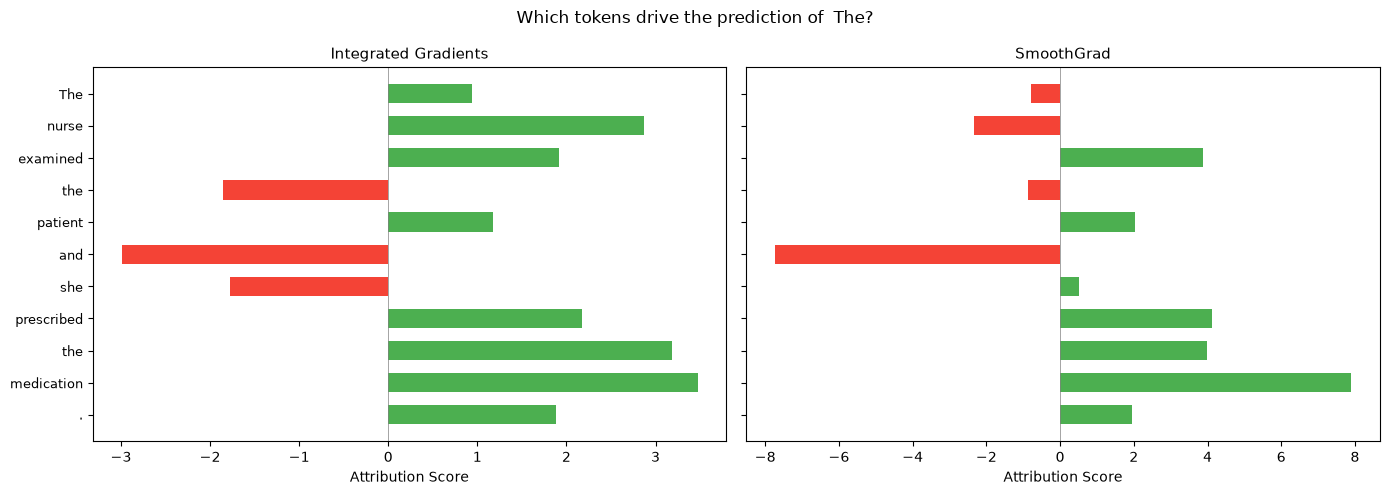

Attribution results logged to W&B.


In [16]:
# --- Side-by-side bar chart ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, max(5, len(token_labels) * 0.45)), sharey=True)

y_pos = range(len(token_labels))

colors_ig = ["#4CAF50" if s >= 0 else "#f44336" for s in ig_scores]
ax1.barh(y_pos, ig_scores, color=colors_ig, height=0.6)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(token_labels, fontsize=9)
ax1.set_title("Integrated Gradients", fontsize=11)
ax1.set_xlabel("Attribution Score")
ax1.invert_yaxis()
ax1.axvline(x=0, color="gray", linewidth=0.5)

colors_sg = ["#4CAF50" if s >= 0 else "#f44336" for s in sg_scores]
ax2.barh(y_pos, sg_scores, color=colors_sg, height=0.6)
ax2.set_title("SmoothGrad", fontsize=11)
ax2.set_xlabel("Attribution Score")
ax2.axvline(x=0, color="gray", linewidth=0.5)

fig.suptitle("Which tokens drive the prediction of " + predicted_word + "?", fontsize=12)
plt.tight_layout()
wandb.log({"attribution/ig_vs_smoothgrad_bars": wandb.Image(fig)})
plt.show()

# --- Colored HTML visualization ---

def scores_to_html(tokens_list, scores, title):
    q = chr(34)  # double quote character
    abs_max = max(abs(s) for s in scores)
    if abs_max == 0:
        normed = [0.0] * len(scores)
    else:
        normed = [s / abs_max for s in scores]

    parts = ['<div style=' + q + 'font-family: monospace; line-height: 2.8; padding: 10px;' + q + '>']
    parts.append('<b>' + title + '</b><br><br>')
    for tok, val in zip(tokens_list, normed):
        if val >= 0:
            r = int(255 * (1 - val * 0.6))
            g = 255
            b = int(255 * (1 - val * 0.6))
        else:
            r = 255
            g = int(255 * (1 + val * 0.6))
            b = int(255 * (1 + val * 0.6))
        style = 'background-color:rgb(' + str(r) + ',' + str(g) + ',' + str(b) + '); '
        style += 'padding:4px 8px; margin:2px; border-radius:4px; '
        style += 'display:inline-block; border: 1px solid #ddd;'
        label_text = tok + ' <small>(' + format(val, '+.2f') + ')</small>'
        parts.append('<span style=' + q + style + q + '>' + label_text + '</span>')
    parts.append('</div>')
    return ''.join(parts)

ig_html = scores_to_html(token_labels, ig_scores, "Integrated Gradients")
sg_html = scores_to_html(token_labels, sg_scores, "SmoothGrad")

display(HTML(ig_html))
display(HTML(sg_html))

# Log to W&B
wandb.log({
    "attribution/ig_colored_html": wandb.Html(ig_html),
    "attribution/smoothgrad_colored_html": wandb.Html(sg_html),
})

# Also log raw scores as a table
attr_df = pd.DataFrame({
    "token": token_labels,
    "ig_score": ig_scores,
    "smoothgrad_score": sg_scores,
})
wandb.log({"attribution/scores_table": wandb.Table(dataframe=attr_df)})
print("Attribution results logged to W&B.")



The bar charts show which tokens pushed the model toward (green) or away from (red) its predicted next word.


- **Where IG and SmoothGrad agree** on the top tokens, we can be more confident those words genuinely matter. Where they disagree, it is because IG traces a single path from "blank" to the real input, while SmoothGrad averages over many slightly different versions.
- **Content words vs function words**: words like "nurse", "prescribed", "medication" should carry more weight than "the" or "and". If small function words show high attribution, the model might be relying on patterns that do not generalize well.
- **Comparison with attention (Objective 1)**: attention shows what the model looks at, attribution shows what actually matters. These are related but different. A head might attend strongly to a token that ultimately has low attribution (it looked at it but did not use it much). This gap is the core of the "attention vs attribution" debate.

## Objective 3: Latent Space Scatter Plot

Does SmolLM-135M internally "know" the difference between sports and finance? Even though nobody trained it as a topic classifier, its internal representations might naturally separate these categories.

We feed 20 sports sentences and 20 finance sentences through the model, pull out the hidden representations from two layers (one early, one late), and use three methods (PCA, t-SNE, UMAP) to squash the 576-dimensional vectors down to 2D for plotting.

If the late layer separates the two groups better than the early layer, that means the model builds up topic understanding as information flows deeper through the network.

In [17]:
sports_sentences = [
    "Rudra scored the winning goal in the final minute of the match.",
    "The coach benched Preeyas after a poor first-half performance.",
    "Dakshya cleared the bar at 1.95 meters to win the high jump.",
    "Shravani bowled six consecutive dot balls in the last over.",
    "Gayatri won the 100-meter sprint with a personal best time.",
    "Thejus saved two penalty kicks to keep the team alive in the shootout.",
    "The referee handed out a yellow card for the rough tackle.",
    "Rudra and Preeyas trained together during the off-season camp.",
    "The stadium was packed for the championship final on Sunday.",
    "Dakshya hit a century in the second innings of the test match.",
    "The swimming relay team broke the national record by three seconds.",
    "Shravani served fourteen aces in the tennis semifinal.",
    "The basketball team won their fifth straight game this season.",
    "Gayatri qualified for the marathon after finishing under three hours.",
    "The cricket board announced the squad for the upcoming tour.",
    "Thejus ran the anchor leg and overtook two runners at the finish.",
    "The football league season will start in the first week of August.",
    "Rudra was named player of the tournament after scoring five goals.",
    "The hockey team trained at the new indoor facility all week.",
    "Preeyas hit the shuttlecock past the net to win the badminton set.",
]

finance_sentences = [
    "The central bank raised interest rates by fifty basis points.",
    "Rudra diversified the portfolio with bonds and index funds.",
    "Quarterly earnings exceeded analyst expectations by a wide margin.",
    "Preeyas closed the deal for a twelve percent stake in the startup.",
    "The stock market dropped sharply after the inflation report came out.",
    "Dakshya submitted the tax returns well before the deadline.",
    "The mutual fund delivered consistent returns over the past five years.",
    "Shravani reviewed the balance sheet and flagged two discrepancies.",
    "The government issued new treasury bonds at a fixed rate.",
    "Gayatri negotiated a lower interest rate on the business loan.",
    "The company reported a net loss for the third consecutive quarter.",
    "Thejus opened a high-yield savings account at the new bank.",
    "Foreign investors pulled capital out of the emerging market.",
    "Rudra calculated the compound interest on a three-year fixed deposit.",
    "The venture capital firm funded three startups in the healthcare sector.",
    "Preeyas hedged the currency risk using forward contracts.",
    "The annual budget allocated more funds to infrastructure spending.",
    "Dakshya audited the expense reports and found unnecessary charges.",
    "The exchange rate fell to a six-month low against the dollar.",
    "Shravani presented the revenue forecast to the board of directors.",
]

all_sentences = sports_sentences + finance_sentences
labels = ["Sports"] * 20 + ["Finance"] * 20

print("Total sentences:", len(all_sentences))
print("  Sports:", len(sports_sentences))
print("  Finance:", len(finance_sentences))

Total sentences: 40
  Sports: 20
  Finance: 20


In [18]:
# Tokenize everything with padding
batch_inputs = tokenizer(
    all_sentences,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=64
)
print("Batch shape:", batch_inputs["input_ids"].shape)

# Forward pass with hidden states
with torch.no_grad():
    batch_outputs = model(
        **batch_inputs,
        output_hidden_states=True
    )

# hidden_states is a tuple of 31 tensors:
#   index 0 = output of the embedding layer
#   index k = output of transformer layer (k-1)
# So layer 2 is at index 3, layer 28 is at index 29

early_layer_idx = 2
late_layer_idx = 28

early_hidden = batch_outputs.hidden_states[early_layer_idx + 1]  # (40, seq_len, 576)
late_hidden = batch_outputs.hidden_states[late_layer_idx + 1]    # (40, seq_len, 576)

print("Early layer", early_layer_idx, "shape:", early_hidden.shape)
print("Late layer", late_layer_idx, "shape:", late_hidden.shape)

# Mean pooling over real tokens (skip padding)
mask = batch_inputs["attention_mask"].unsqueeze(-1).float()  # (40, seq_len, 1)

early_pooled = (early_hidden * mask).sum(dim=1) / mask.sum(dim=1)  # (40, 576)
late_pooled = (late_hidden * mask).sum(dim=1) / mask.sum(dim=1)    # (40, 576)

early_np = early_pooled.numpy()
late_np = late_pooled.numpy()
print("Pooled shapes:", early_np.shape, late_np.shape)

Batch shape: torch.Size([40, 19])
Early layer 2 shape: torch.Size([40, 19, 576])
Late layer 28 shape: torch.Size([40, 19, 576])
Pooled shapes: (40, 576) (40, 576)


In [19]:
import umap

# PCA
pca_early = PCA(n_components=2).fit_transform(early_np)
pca_late = PCA(n_components=2).fit_transform(late_np)
print("PCA done.")

# t-SNE (perplexity is low because we only have 40 points)
tsne_early = TSNE(n_components=2, perplexity=10, random_state=42, max_iter=1000).fit_transform(early_np)
tsne_late = TSNE(n_components=2, perplexity=10, random_state=42, max_iter=1000).fit_transform(late_np)
print("t-SNE done.")

# UMAP (n_neighbors is low for the same reason)
umap_early = umap.UMAP(n_components=2, n_neighbors=10, random_state=42).fit_transform(early_np)
umap_late = umap.UMAP(n_components=2, n_neighbors=10, random_state=42).fit_transform(late_np)
print("UMAP done.")

PCA done.
t-SNE done.
UMAP done.


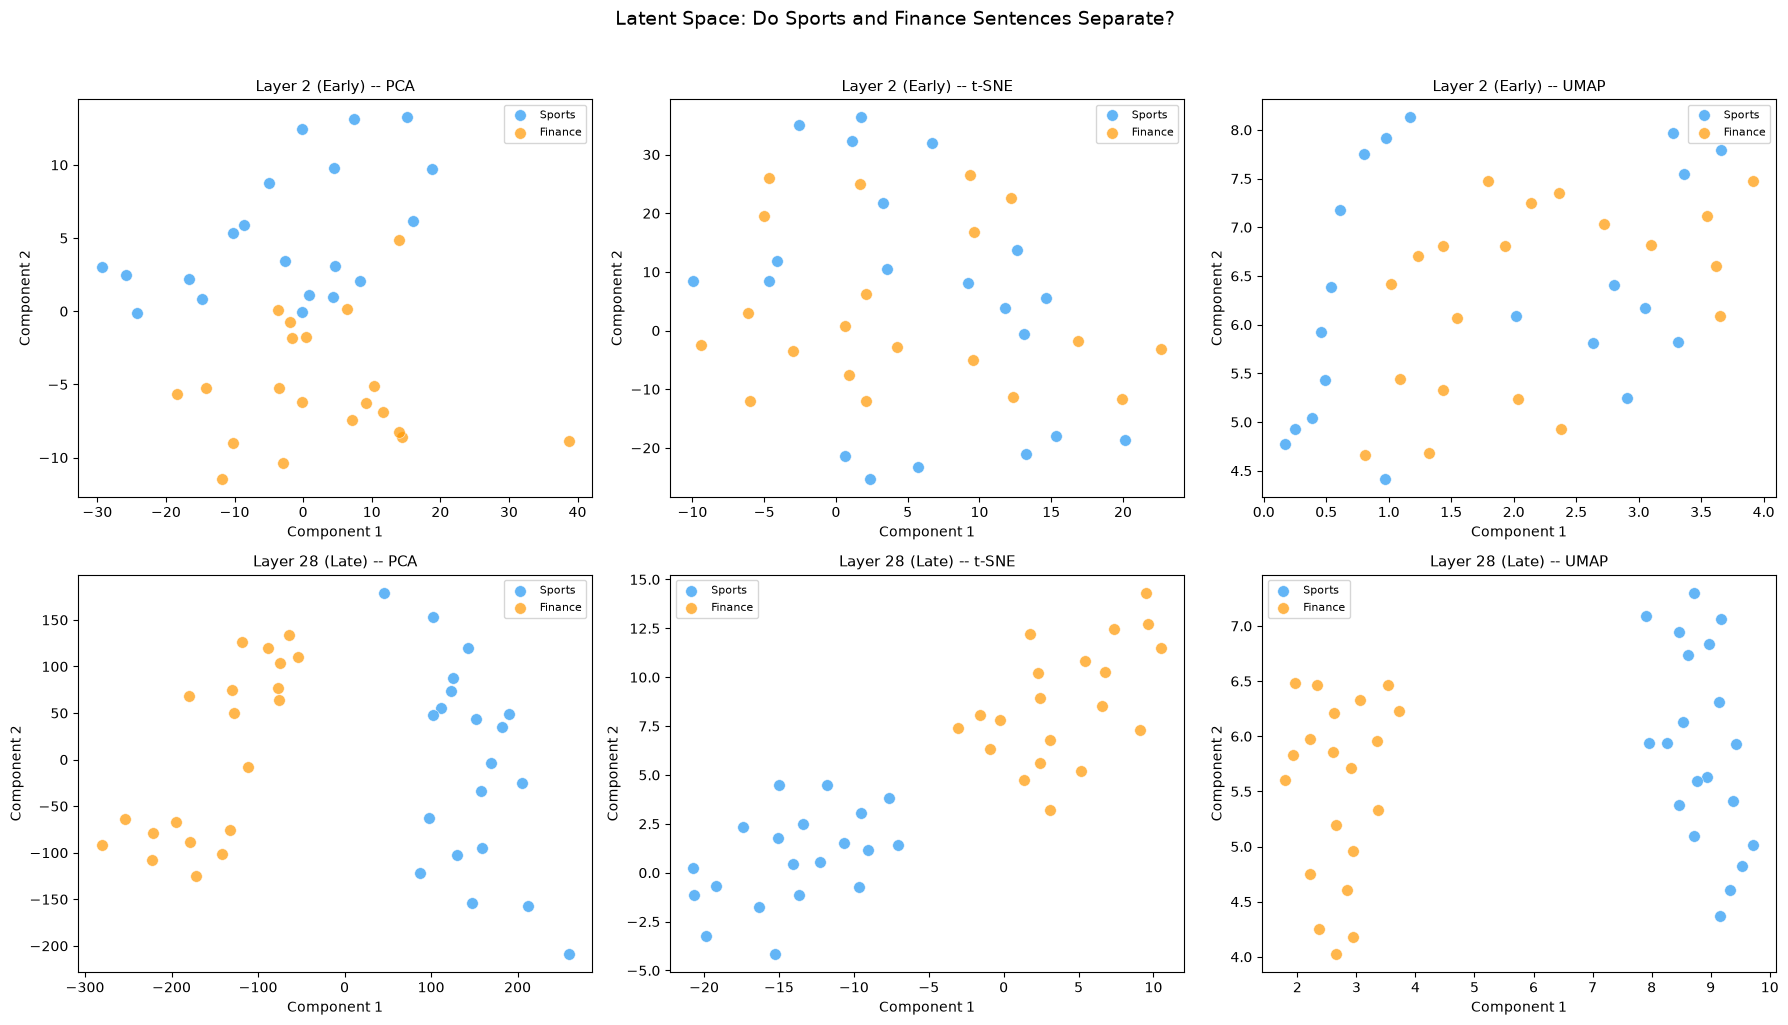

All scatter plots logged to W&B.


In [20]:
methods = ["PCA", "t-SNE", "UMAP"]
early_results = [pca_early, tsne_early, umap_early]
late_results = [pca_late, tsne_late, umap_late]

sport_color = "#2196F3"
finance_color = "#FF9800"

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, (method, early_data, late_data) in enumerate(zip(methods, early_results, late_results)):
    # Early layer row
    ax = axes[0][col]
    ax.scatter(early_data[:20, 0], early_data[:20, 1],
               c=sport_color, label="Sports", alpha=0.7, s=70, edgecolors="white", linewidth=0.5)
    ax.scatter(early_data[20:, 0], early_data[20:, 1],
               c=finance_color, label="Finance", alpha=0.7, s=70, edgecolors="white", linewidth=0.5)
    ax.set_title(f"Layer {early_layer_idx} (Early) -- {method}", fontsize=11)
    ax.legend(fontsize=8)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

    # Late layer row
    ax = axes[1][col]
    ax.scatter(late_data[:20, 0], late_data[:20, 1],
               c=sport_color, label="Sports", alpha=0.7, s=70, edgecolors="white", linewidth=0.5)
    ax.scatter(late_data[20:, 0], late_data[20:, 1],
               c=finance_color, label="Finance", alpha=0.7, s=70, edgecolors="white", linewidth=0.5)
    ax.set_title(f"Layer {late_layer_idx} (Late) -- {method}", fontsize=11)
    ax.legend(fontsize=8)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

fig.suptitle("Latent Space: Do Sports and Finance Sentences Separate?", fontsize=14, y=1.02)
plt.tight_layout()
wandb.log({"latent/scatter_grid": wandb.Image(fig)})
plt.show()

# Also log each plot individually for cleaner W&B panels
for col, (method, early_data, late_data) in enumerate(zip(methods, early_results, late_results)):
    for layer_name, data, l_idx in [("early", early_data, early_layer_idx), ("late", late_data, late_layer_idx)]:
        fig_s, ax_s = plt.subplots(figsize=(6, 5))
        ax_s.scatter(data[:20, 0], data[:20, 1], c=sport_color, label="Sports", alpha=0.7, s=70, edgecolors="white")
        ax_s.scatter(data[20:, 0], data[20:, 1], c=finance_color, label="Finance", alpha=0.7, s=70, edgecolors="white")
        ax_s.set_title(f"Layer {l_idx} ({layer_name.title()}) -- {method}")
        ax_s.legend()
        ax_s.set_xlabel("Component 1")
        ax_s.set_ylabel("Component 2")
        plt.tight_layout()
        key = f"latent/{layer_name}_{method.lower().replace(chr(45), chr(95))}"
        wandb.log({key: wandb.Image(fig_s)})
        plt.close(fig_s)

print("All scatter plots logged to W&B.")

how the model builds up representations through its layers:

**Early layer (Layer 2)**: The points are likely mixed together with no clear boundary between Sports and Finance. At this depth, the model is still working with raw word-level patterns and has not built sentence-level meaning yet.

**Late layer (Layer 28)**: We should see more grouping here. After 28 layers of computation, the model has had time to figure out what each sentence is about. If the points cluster by topic, it means the model has organically learned to distinguish these categories even though it was never trained to classify.

**PCA vs t-SNE vs UMAP**: PCA finds the directions with the most overall spread. It is simple and honest, but it can only capture straight-line patterns. t-SNE is better at revealing clusters, but it can mislead because it distorts distances between groups (two clusters might look equally far apart when they are not). UMAP balances local detail with global structure and tends to give a more faithful picture than t-SNE.

If none of the methods show clear separation even in the late layer, that is also a valid finding. SmolLM-135M is a general-purpose language model. Its job is to predict the next word, not to classify sentences, so its internal layout may not align with human topic categories.

## Safety Audit

Pulling everything together: should we deploy SmolLM-135M for automated text completion?

### What the attention analysis tells us about safety

The attention heatmap showed whether the model tracks pronoun references correctly. If it links "she" to "nurse," that is evidence of basic syntactic competence. But some heads attend to irrelevant tokens, which means the model is not uniformly reliable. The three-names experiment also revealed a bias when the reference is ambiguous, and any systematic bias in pronoun resolution is a safety concern for real-world text generation.

### What the attribution analysis tells us about safety

The gradient-based attribution showed which words actually drive predictions. If the model relies on meaningful content words (nouns, verbs), that is a good sign. If high attribution lands on punctuation, articles, or seemingly random tokens, the model might be picking up spurious patterns rather than genuine language understanding. The comparison between IG and SmoothGrad also measures how stable the explanations are. If two different methods disagree on what matters, the model becomes harder to trust.

### What the latent space analysis tells us about safety

The scatter plots showed whether the model builds coherent internal representations that separate different topics. Good separation in late layers means the model organizes information sensibly. Poor separation means it might blend unrelated domains, which could be risky if deployed in a specific setting where mixing up topics would be harmful.

### Recommendation

Based on the three analyses:

1. **Pronoun resolution** (Attention): Does the model handle basic language structure? Check the best-head weight.
2. **Prediction basis** (Attribution): Is the model relying on reasonable features? Check whether content words dominate.
3. **Internal coherence** (Latent space): Does the model build organized representations? Check cluster separation.

A model that performs well on all three is safer to deploy. Weaknesses in any area suggest deploying with guardrails (human review, restricted domains, output filtering) or additional fine-tuning before release.

In [ ]:
wandb.finish()

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


attention/best_head,▁
attention/best_layer,▁
attention/she_to_nurse_weight,▁
attention/three_names_top_weight,▁
attention/best_head,8
attention/best_layer,5
attention/she_to_nurse_weight,0.60067
attention/three_names_top_token,","
attention/three_names_top_weight,0.29889


W&B run complete!

To create your public report:
  1. Go to your W&B run URL (printed when we started the run)
  2. Click Create Report in the top right
  3. Add all the logged images and tables
  4. Click the Share button and set visibility to Public
  5. Copy the report URL for your submission
